In [67]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()))))
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()), 'model')))
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()), '../../src')))

In [68]:
import torch
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# TensOps library
import tensopsciml as to
from tensopsciml import TensOps

# Functions of PGNNIV example
from model.architecture.PGNNIV_architecture import PGNNIV
from model.utils.load_data import load_data
from model.utils.split_data import get_train_val_indices, train_val_split_torch_tensops
from model.utils.checkpoints import load_results

from visualizers.utils.error import relative_error_stats
from visualizers.utils.plots import plot_tensors

In [69]:
SEED = 42

np.random.seed(SEED)  
torch.manual_seed(SEED)  
GEN = torch.Generator().manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

if DEVICE.type == 'cuda':
    torch.cuda.manual_seed(SEED)

Using device: cuda


## Data and results load

In [70]:
data_name = 'Ogden_N1000_S0_train'
model_name = 'PGNNIV_baseline'

# Paths definition
ROOT_PATH = os.path.abspath(os.path.join(os.path.dirname(os.getcwd()), '../pgnniv'))
DATA_FOLDER_PATH = os.path.join(ROOT_PATH, 'datasets', 'train_data', 'data')
RESULTS_FOLDER_PATH = os.path.join(ROOT_PATH, 'results')

DATA_PATH = os.path.join(DATA_FOLDER_PATH, data_name) + '.pkl'
MODEL_RESULTS_PATH = os.path.join(RESULTS_FOLDER_PATH, model_name, data_name)

In [71]:
dataset = load_data(DATA_PATH)

Data successfully loaded from: /home/rmunoz/Escritorio/rmunozTMELab/TensOps/nb/examples/pgnniv/datasets/train_data/data/Ogden_N1000_S0_train.pkl


In [72]:
N_DATA = dataset['N_DATA']
TRAIN_SPLIT = 0.7
TEST_SPLIT = 1 - TRAIN_SPLIT

dx = dataset['x_step_size']
dy = dataset['y_step_size']
D = to.Derivative(dx, dy, 0, indexing="xy").two_dimensions()

In [73]:
U_dataset = dataset['U']
F_dataset = dataset['F']
E_dataset = dataset['E']
P_dataset = dataset['P']
Tx_dataset, Ty_dataset = dataset['Tx'], dataset['Ty']
lambda1, lambda2, lambda3 = dataset['lambda1'], dataset['lambda2'], dataset['lambda3']

In [74]:
# Displacement field U(x, y)
U = torch.zeros(U_dataset.shape[0], 2, U_dataset.shape[1], U_dataset.shape[2], dtype=torch.float32)
U[:, 0] = torch.tensor(U_dataset[..., 0], dtype=torch.float32)
U[:, 1] = torch.tensor(U_dataset[..., 1], dtype=torch.float32)
U = TensOps(U.to(DEVICE), domain_dim=2, codomain_dim=[2], order=[1, 0], contravariant_indices=[0], covariant_indices=None)

# Gradient field FF(x, y)
F = torch.zeros(F_dataset.shape[0], 2, 2, F_dataset.shape[1]-1, F_dataset.shape[2]-1)
F[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(F_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
F[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(F_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
F = TensOps(F.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])

# Green-Lagrange tensor EE(x, y)
E = torch.zeros(E_dataset.shape[0], 2, 2, E_dataset.shape[1]-1, E_dataset.shape[2]-1)
E[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(E_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
E[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(E_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
E = TensOps(E.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])

# First Piola-Kirchhoff stress P(x, y). P^{ij}, order [2, 0].
P = torch.zeros(P_dataset.shape[0], 2, 2, P_dataset.shape[1]-1, P_dataset.shape[2]-1)
P[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(P_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
P[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(P_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
P = TensOps(P.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[2, 0], contravariant_indices=[0, 1], covariant_indices=None)

# Boundary tractions T^i = P^{ij} N_j (full traction vectors), already
# cell-averaged and reshaped to (N, 2, Ny-1, 1) / (N, 2, 1, Nx-1) by the data
# generator.
Tx = torch.tensor(Tx_dataset, dtype=torch.float32)
Ty = torch.tensor(Ty_dataset, dtype=torch.float32)

In [75]:
train_idx, val_idx = get_train_val_indices(N_DATA, TRAIN_SPLIT, GEN)

U_train, U_test = train_val_split_torch_tensops(U, train_idx, val_idx)
F_train, F_test = train_val_split_torch_tensops(F, train_idx, val_idx)
E_train, E_test = train_val_split_torch_tensops(E, train_idx, val_idx)
P_train, P_test = train_val_split_torch_tensops(P, train_idx, val_idx)
Tx_train, Tx_test = train_val_split_torch_tensops(Tx, train_idx, val_idx)
Ty_train, Ty_test = train_val_split_torch_tensops(Ty, train_idx, val_idx)

lambda1_train, lambda1_test = train_val_split_torch_tensops(torch.tensor(lambda1), train_idx, val_idx)
lambda2_train, lambda2_test = train_val_split_torch_tensops(torch.tensor(lambda2), train_idx, val_idx)
lambda3_train, lambda3_test = train_val_split_torch_tensops(torch.tensor(lambda3), train_idx, val_idx)

In [76]:
# Model parameters
latent_space_predictive = 10
n_filters_explanatory = 10

# Predictive network architecture
input_shape_1 = Tx[0].shape
input_shape_2 = Ty[0].shape
predictive_layers = [50, 20, latent_space_predictive, 20, 50]
predictive_output = U.values[0].shape

# Explanatory network architecture
explanatory_input = E.values[0].shape
explanatory_layers = [50]
explanatory_output = P.values[0].shape

# Metric of the problem: Euclidean (Cartesian) g_{ij} = delta_{ij} on the
# interior grid where GradU/E/P live. Built once here as a batch-1 MetrOps and
# passed into the model, which broadcasts it to each step's batch size.
grid = E.values.shape[-2:]
metric_ = torch.eye(2, dtype=torch.float32).reshape(1, 2, 2, 1, 1).expand(1, 2, 2, *grid).clone()
metric = to.MetrOps(metric_.to(DEVICE), domain_dim=2, codomain_dim=[2, 2])

In [77]:
pgnniv_model = PGNNIV(input_shape_1, input_shape_2, predictive_layers, predictive_output,
                      explanatory_input, explanatory_layers, explanatory_output,
                      n_filters_explanatory, D, metric).to(DEVICE)

optimizer = torch.optim.Adam(pgnniv_model.parameters(), lr=1e-3)

In [78]:
model, optimizer, lists = load_results(pgnniv_model, optimizer, MODEL_RESULTS_PATH, map_location=DEVICE)

In [79]:
time_list = lists['time_list']

train_total_loss_list = lists['train_total_loss_list']
train_R1_loss_list = lists['train_R1_loss_list']
train_R2_loss_list = lists['train_R2_loss_list']
train_R3_loss_list = lists['train_R3_loss_list']
train_R4_loss_list = lists['train_R4_loss_list']

test_total_loss_list = lists['test_total_loss_list']
test_R1_loss_list = lists['test_R1_loss_list']
test_R2_loss_list = lists['test_R2_loss_list']
test_R3_loss_list = lists['test_R3_loss_list']
test_R4_loss_list = lists['test_R4_loss_list']

## Plots

In [80]:
def smooth_curve(data, window_size=1000):
    window = np.ones(window_size) / window_size
    return np.convolve(data, window, mode='valid')

def cm_to_in(cm):
    return cm * 0.393701

def normalize_list(lst):
    max_testue = np.max(lst)
    return [x / max_testue for x in lst]

linewidth = 1.5  
title_fontsize = 14  
label_fontsize = 14  
legend_fontsize = 12 
tick_fontsize = 11  

# plt.rc('text', usetex=True)
plt.rc('font', family='serif')

posX = cm_to_in(10) 
posY = cm_to_in(10) 
width = cm_to_in(12) 
height = cm_to_in(8)

color = [0.1, 0, 0.8]
subplot_adjust_left = cm_to_in(0.15)
subplot_adjust_bottom = cm_to_in(0.15)

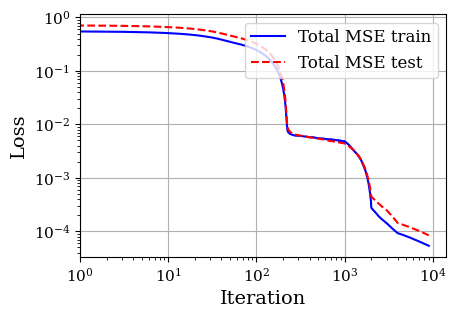

In [81]:
plt.figure(figsize=(width, height))

plt.plot(smooth_curve(train_total_loss_list), label='Total MSE train', color='blue', linestyle='-')
plt.plot(smooth_curve(test_total_loss_list), label='Total MSE test', color='red', linestyle='--')

plt.xlabel('Iteration', fontsize=label_fontsize)
plt.ylabel('Loss', fontsize=label_fontsize)

plt.grid(True)
plt.legend(loc='upper right', fontsize=legend_fontsize)
plt.tick_params(axis='both', which='major', labelsize=tick_fontsize)

plt.xscale('log')
plt.yscale('log')
plt.xlim(left=1) 

plt.show()

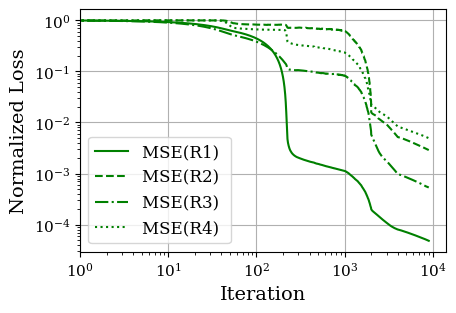

In [82]:
plt.figure(figsize=(width, height))

plt.plot(normalize_list(smooth_curve(train_R1_loss_list)), label=r'MSE(R1) ', color='green', linestyle='-')
plt.plot(normalize_list(smooth_curve(train_R2_loss_list)), label=r'MSE(R2) ', color='green', linestyle='--')
plt.plot(normalize_list(smooth_curve(train_R3_loss_list)), label=r'MSE(R3) ', color='green', linestyle='-.')
plt.plot(normalize_list(smooth_curve(train_R4_loss_list)), label=r'MSE(R4) ', color='green', linestyle=':')

plt.xlabel('Iteration', fontsize=label_fontsize)
plt.ylabel('Normalized Loss', fontsize=label_fontsize)

plt.grid(True)
plt.legend(loc='lower left', fontsize=legend_fontsize)
plt.tick_params(axis='both', which='major', labelsize=tick_fontsize)

plt.xscale('log')
plt.yscale('log')
plt.xlim(left=1) 

plt.show()

In [83]:
U_pred, F_pred, E_pred, P_pred, Tx_pred, Ty_pred = pgnniv_model(Tx_test, Ty_test)

### $U(x,y)$

In [84]:
Ux_validation = U_test.values[:, 0].cpu().detach()
Ux_prediction = U_pred.values[:, 0].cpu().detach()

relative_error_stats(Ux_validation, Ux_prediction, dx, dy)

Relative error:
 Minimum: 4.02e-04
 First quartile (Q1): 8.28e-04
 Median (Q2): 1.51e-03
 Third quartile (Q3): 3.15e-03
 Maximum: 2.82e-01


In [85]:
Uy_validation = U_test.values[:, 0].cpu().detach()
Uy_prediction = U_pred.values[:, 0].cpu().detach()

relative_error_stats(Uy_validation, Uy_prediction, dx, dy)

Relative error:
 Minimum: 4.02e-04
 First quartile (Q1): 8.28e-04
 Median (Q2): 1.51e-03
 Third quartile (Q3): 3.15e-03
 Maximum: 2.82e-01


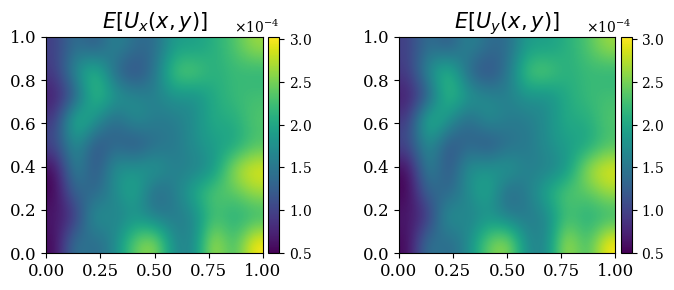

In [86]:
titles = ['$E[U_{x}(x, y)]$', '$E[U_{y}(x, y)]$', ]
plot_tensors([torch.mean(torch.abs(Ux_prediction - Ux_validation), axis=0), 
              torch.mean(torch.abs(Uy_prediction - Uy_validation), axis=0), 
              ], titles)

### $E(x,y)$

In [87]:
E_xx_validation = F_test.values[:, 0, 0].cpu().detach()
E_xx_prediction = F_pred.values[:, 0, 0].cpu().detach()

relative_error_stats(E_xx_validation, E_xx_prediction, dx, dy)

Relative error:
 Minimum: 4.67e-04
 First quartile (Q1): 6.94e-04
 Median (Q2): 8.20e-04
 Third quartile (Q3): 1.13e-03
 Maximum: 3.83e-03


In [88]:
E_yy_validation = E_test.values[:, 1, 1].cpu().detach()
E_yy_prediction = E_pred.values[:, 1, 1].cpu().detach()

relative_error_stats(E_yy_validation, E_yy_prediction, dx, dy)

Relative error:
 Minimum: 1.72e-03
 First quartile (Q1): 2.70e-03
 Median (Q2): 4.17e-03
 Third quartile (Q3): 8.56e-03
 Maximum: 7.08e-01


In [89]:
E_xy_validation = E_test.values[:, 0, 1].cpu().detach()
E_xy_prediction = E_pred.values[:, 0, 1].cpu().detach()

relative_error_stats(E_xy_validation, E_xy_prediction, dx, dy)

Absolute error (denominator = 0):
 Minimum: 6.45e-04
 First quartile (Q1): 8.35e-04
 Median (Q2): 1.08e-03
 Third quartile (Q3): 1.69e-03
 Maximum: 3.56e-03


/home/rmunoz/Escritorio/rmunozTMELab/TensOps/nb/examples/pgnniv/visualizers/utils/error.py:31: Warning: Denominator = 0 --> Absolute error
  warnings.warn("Denominator = 0 --> Absolute error", Warning)


In [90]:
E_yx_validation = E_test.values[:, 1, 0].cpu().detach()
E_yx_prediction = E_pred.values[:, 1, 0].cpu().detach()

relative_error_stats(E_yx_validation, E_yx_prediction, dx, dy)

Absolute error (denominator = 0):
 Minimum: 6.45e-04
 First quartile (Q1): 8.35e-04
 Median (Q2): 1.08e-03
 Third quartile (Q3): 1.69e-03
 Maximum: 3.56e-03


/home/rmunoz/Escritorio/rmunozTMELab/TensOps/nb/examples/pgnniv/visualizers/utils/error.py:31: Warning: Denominator = 0 --> Absolute error
  warnings.warn("Denominator = 0 --> Absolute error", Warning)


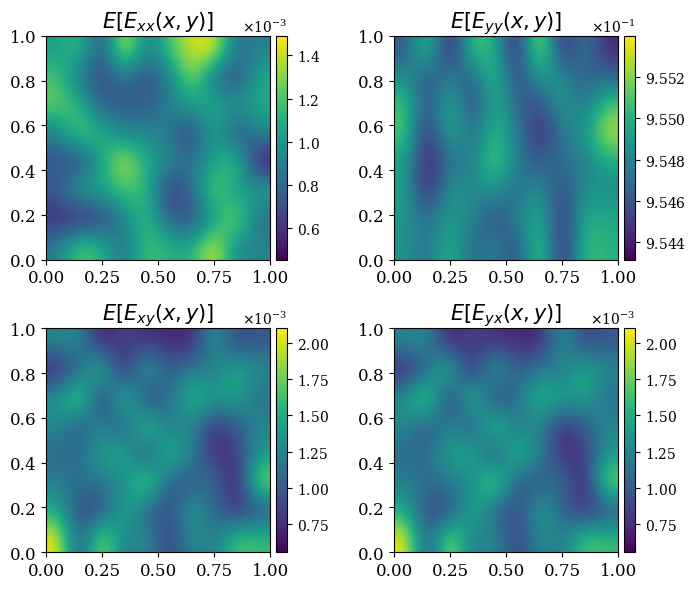

In [91]:
titles = ['$E[E_{xx}(x, y)]$', '$E[E_{yy}(x, y)]$', '$E[E_{xy}(x, y)]$', '$E[E_{yx}(x, y)]$']
plot_tensors([torch.mean(torch.abs(E_xx_prediction - E_xx_validation), axis=0), 
              torch.mean(torch.abs(E_xx_prediction - E_yy_validation), axis=0), 
              torch.mean(torch.abs(E_xy_prediction - E_xy_validation), axis=0), 
              torch.mean(torch.abs(E_yx_prediction - E_yx_validation), axis=0), 
              ], titles)

### $P(x,y)$ — first Piola-Kirchhoff stress

In [92]:
P_xx_validation = P_test.values[:, 0, 0].cpu().detach()
P_xx_prediction = P_pred.values[:, 0, 0].cpu().detach()

relative_error_stats(P_xx_validation, P_xx_prediction, dx, dy)

Relative error:
 Minimum: 1.14e-03
 First quartile (Q1): 1.93e-03
 Median (Q2): 2.93e-03
 Third quartile (Q3): 4.91e-03
 Maximum: 1.47e-01


In [93]:
P_yy_validation = P_test.values[:, 1, 1].cpu().detach()
P_yy_prediction = P_pred.values[:, 1, 1].cpu().detach()

relative_error_stats(P_yy_validation, P_yy_prediction, dx, dy)

Relative error:
 Minimum: 9.81e-04
 First quartile (Q1): 1.53e-03
 Median (Q2): 2.63e-03
 Third quartile (Q3): 4.46e-03
 Maximum: 6.53e-02


In [94]:
P_xy_validation = P_test.values[:, 0, 1].cpu().detach()
P_xy_prediction = P_pred.values[:, 0, 1].cpu().detach()

relative_error_stats(P_xy_validation, P_xy_prediction, dx, dy)

Absolute error (denominator = 0):
 Minimum: 1.78e-01
 First quartile (Q1): 2.96e-01
 Median (Q2): 3.86e-01
 Third quartile (Q3): 5.90e-01
 Maximum: 1.47e+00


/home/rmunoz/Escritorio/rmunozTMELab/TensOps/nb/examples/pgnniv/visualizers/utils/error.py:31: Warning: Denominator = 0 --> Absolute error
  warnings.warn("Denominator = 0 --> Absolute error", Warning)


In [95]:
P_yx_validation = P_test.values[:, 1, 0].cpu().detach()
P_yx_prediction = P_pred.values[:, 1, 0].cpu().detach()

relative_error_stats(P_yx_validation, P_yx_prediction, dx, dy)

Absolute error (denominator = 0):
 Minimum: 1.50e-01
 First quartile (Q1): 2.51e-01
 Median (Q2): 3.11e-01
 Third quartile (Q3): 5.22e-01
 Maximum: 1.37e+00


/home/rmunoz/Escritorio/rmunozTMELab/TensOps/nb/examples/pgnniv/visualizers/utils/error.py:31: Warning: Denominator = 0 --> Absolute error
  warnings.warn("Denominator = 0 --> Absolute error", Warning)


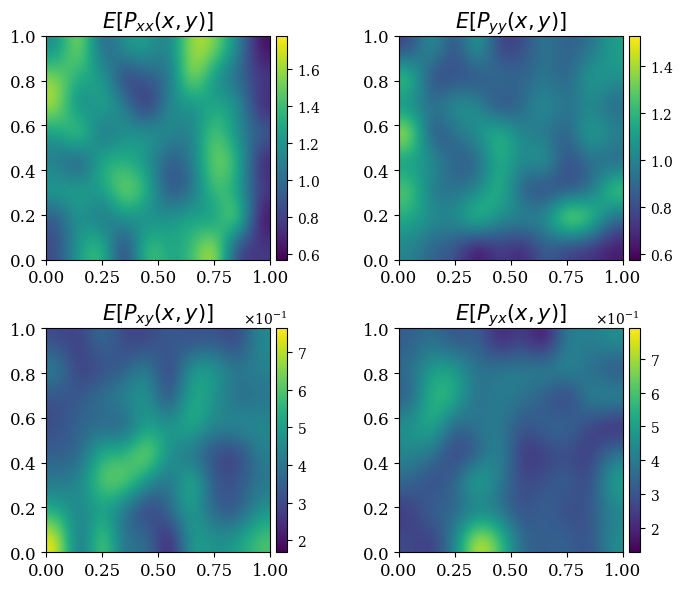

In [96]:
titles = ['$E[P_{xx}(x, y)]$', '$E[P_{yy}(x, y)]$', '$E[P_{xy}(x, y)]$', '$E[P_{yx}(x, y)]$']
plot_tensors([torch.mean(torch.abs(P_xx_prediction - P_xx_validation), axis=0), 
              torch.mean(torch.abs(P_yy_prediction - P_yy_validation), axis=0), 
              torch.mean(torch.abs(P_xy_prediction - P_xy_validation), axis=0), 
              torch.mean(torch.abs(P_yx_prediction - P_yx_validation), axis=0), 
              ], titles)

# Predictions

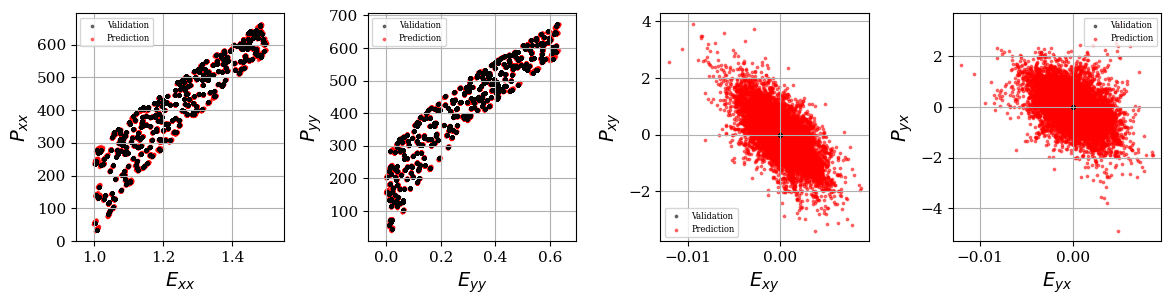

In [97]:
fig, axes = plt.subplots(1, 4, figsize=(2.5*width, height))
order = [1, 0] 

def configure_subplot(ax, E_pred, P_pred, E_val, P_val, xlabel, ylabel, loclegend):
    ax.scatter(E_pred.flatten(), P_pred.flatten(), label='Prediction', color='red', s=3, alpha=0.5)
    ax.scatter(E_val.flatten(), P_val.flatten(), label='Validation', color='black', s=3, alpha=0.5)
    ax.set_xlabel(xlabel, fontsize=label_fontsize)
    ax.set_ylabel(ylabel, fontsize=label_fontsize)
    ax.grid(True)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend([handles[idx] for idx in order], [labels[idx] for idx in order], loc=loclegend, fontsize=legend_fontsize/2)
    ax.tick_params(axis='both', which='major', labelsize=tick_fontsize)
    min_val = torch.min(E_pred.flatten()) - 0.1 * (torch.max(E_pred.flatten()) - torch.min(E_val.flatten()))
    max_val = torch.max(E_pred.flatten()) + 0.1 * (torch.max(E_pred.flatten()) - torch.min(E_val.flatten()))
    ax.set_xlim(min_val, max_val)

configure_subplot(axes[0], E_xx_prediction, P_xx_prediction, E_xx_validation, P_xx_validation, '$E_{xx}$', r'$P_{xx}$', 'upper left')
configure_subplot(axes[1], E_yy_prediction, P_yy_prediction, E_yy_validation, P_yy_validation, '$E_{yy}$', r'$P_{yy}$', 'upper left')
configure_subplot(axes[2], E_xy_prediction, P_xy_prediction, E_xy_validation, P_xy_validation, '$E_{xy}$', r'$P_{xy}$', 'lower left')
configure_subplot(axes[3], E_yx_prediction, P_yx_prediction, E_yx_validation, P_yx_validation, '$E_{yx}$', r'$P_{yx}$', 'upper right')

plt.tight_layout()
plt.show()

In [98]:
E_Ux = relative_error_stats(Ux_validation, Ux_prediction, dx, dy, print_error=False, return_error=True)
E_Uy = relative_error_stats(Uy_validation, Uy_prediction, dx, dy, print_error=False, return_error=True)
E_Exx = relative_error_stats(E_xx_validation, E_xx_prediction, dx, dy, print_error=False, return_error=True)
E_Eyy = relative_error_stats(E_yy_validation, E_yy_prediction, dx, dy, print_error=False, return_error=True)
E_Pxx = relative_error_stats(P_xx_validation, P_xx_prediction, dx, dy, print_error=False, return_error=True)
E_Pyy = relative_error_stats(P_yy_validation, P_yy_prediction, dx, dy, print_error=False, return_error=True)

a = lambda1_test
b = lambda2_test
c = lambda3_test

Ux


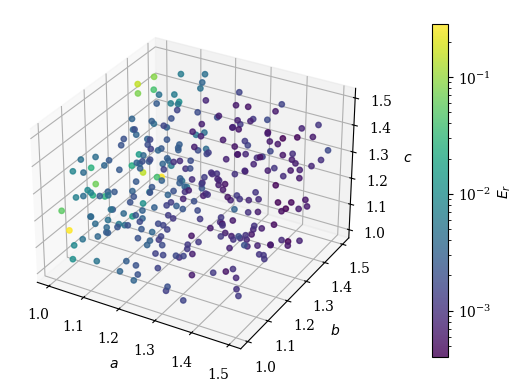

Uy


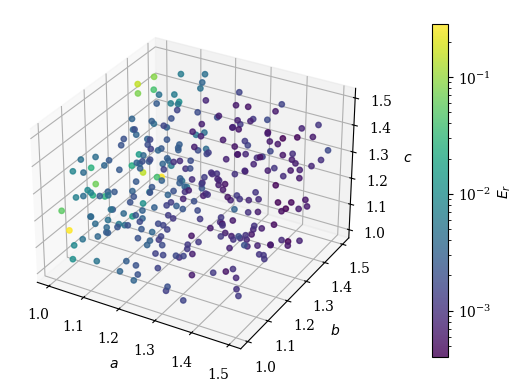

Exx


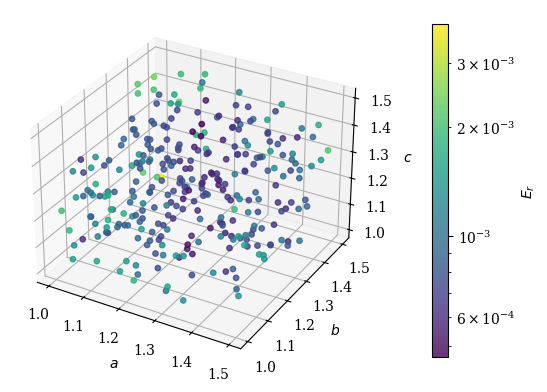

Eyy


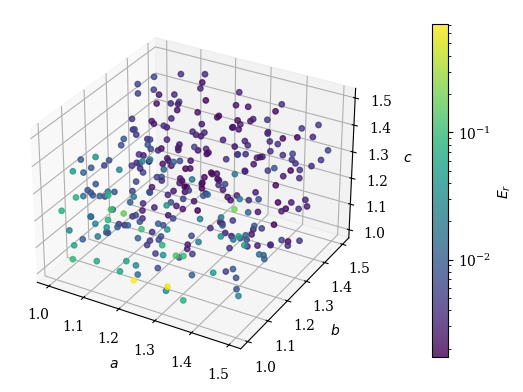

Sxx


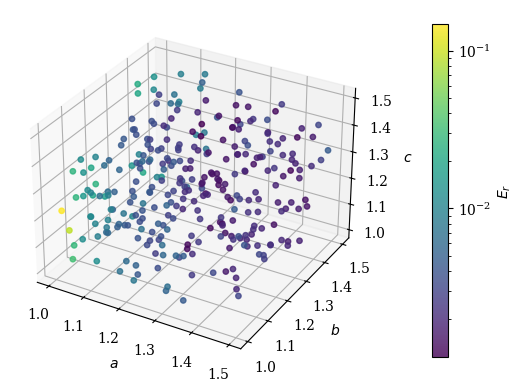

Syy


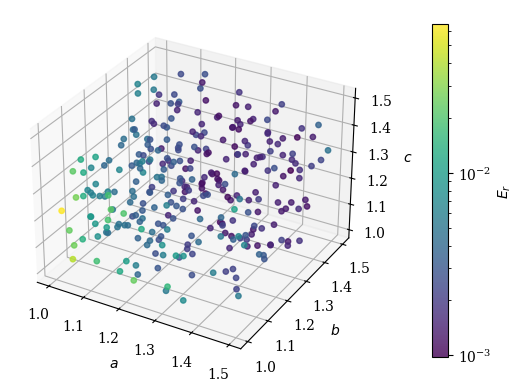

In [99]:
def plot_prediction_error(a, b, c, error, variable):

    print(variable)

    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    sc = ax.scatter(a, b, c, c=error, cmap='viridis', s=15, alpha=0.8, norm=mcolors.LogNorm())
    cbar = plt.colorbar(sc, pad=0.12, shrink=0.9)
    cbar.set_label('$E_r$')

    ax.set_xlabel('$a$')
    ax.set_ylabel('$b$')
    ax.set_zlabel('$c$')

    plt.show()

plot_prediction_error(a=a, b=b, c=c, error=E_Ux, variable='Ux')
plot_prediction_error(a=a, b=b, c=c, error=E_Uy, variable='Uy')
plot_prediction_error(a=a, b=b, c=c, error=E_Exx, variable='Exx')
plot_prediction_error(a=a, b=b, c=c, error=E_Eyy, variable='Eyy')
plot_prediction_error(a=a, b=b, c=c, error=E_Pxx, variable='Sxx')
plot_prediction_error(a=a, b=b, c=c, error=E_Pyy, variable='Syy')